In [1]:
import casadi
import random
import cvxpy as cp
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import time
from pytope import Polytope
from matplotlib.patches import Ellipse
import matplotlib.animation as animation
import matplotlib.image as mpimg

from Initial_Set_Estimation import Initial_Set_Estimation
from Planner_P import Planner_P

%matplotlib inline

In [2]:
EV_Data    = np.load('EV_Data.npy',  allow_pickle = True).item( )
SV0_Data   = np.load('SV0_Data.npy', allow_pickle = True).item( )
SV1_Data   = np.load('SV1_Data.npy', allow_pickle = True).item( )
SV2_Data   = np.load('SV2_Data.npy', allow_pickle = True).item( )
x_track_sv = EV_Data['x_track_sv']
y_track_sv = EV_Data['y_track_sv']
x_track_ev = EV_Data['x_track_ev']
y_track_ev = EV_Data['y_track_ev']

In [3]:
x_EV_initial  = np.array([EV_Data['x'][0],  EV_Data['y'][0],  EV_Data['h'][0],  EV_Data['v'][0]])
x_SV0_initial = np.array([SV0_Data['x'][0], SV0_Data['y'][0], SV0_Data['h'][0], SV0_Data['v'][0]])
x_SV1_initial = np.array([SV1_Data['x'][0], SV1_Data['y'][0], SV1_Data['h'][0], SV1_Data['v'][0]])
x_SV2_initial = np.array([SV2_Data['x'][0], SV2_Data['y'][0], SV2_Data['h'][0], SV2_Data['v'][0]])

T             = 0.24
v_target      = 50/3.6
N_EV          = 7 
N_SV          = 7
v_target_ev   = v_target 
v_target_sv   = v_target
infinity      = 1000000 # infinity
l_veh         = 4.49 # vehicle length, m
w_veh         = 1.98 # vehicle width, m
l_veh_sv0     = 4.46
w_veh_sv0     = 2.06
l_veh_sv1     = 5.17
w_veh_sv1     = 2.13
l_veh_sv2     = 4.96
w_veh_sv2     = 2.17
DEV           = 4   # dimenstion of EV
DSV           = 4   # dimenstion of SV
num_points_sv = len(x_track_sv)

In [4]:
A_SV  = np.array([[1, T, 0, 0], [0, 1, 0, 0], [0, 0, 1, T], [0, 0, 0, 1]])
B_SV  = np.array([[0.5*T**2, 0], [T, 0], [0, 0.5*T**2], [0, T]])
min_ay    = -7
max_ay    = 7
min_ax    = -7
max_ax    = 7
U_SV_Poly = Polytope([[0, min_ay], [max_ax, 0], [0, max_ay], [min_ax, 0]])
q_robust  = np.zeros((2, 1))
Q_robust  = np.diag([7**2, 7**2])
H         = U_SV_Poly.A
h         = U_SV_Poly.b
nu        = 2
nx        = 4
d_min     = 2*np.sqrt((l_veh/2)**2 + (w_veh/2)**2)

In [5]:
N_Car  = 4
opts_Parameters_EV = { 
    'T': T,     
    'N': N_EV,
    'l_f': 1.65,
    'l_r': 1.65,
    'DEV': DEV,
    'nu': nu,
    'nx': nx,
    'A_SV': A_SV,
    'B_SV': B_SV,
    'infinity': infinity,
    'Q1': 10, # steering wheel angle
    'Q2': 1,  # longitudinal acc
    'Q3': 1,  # x & y pos. error
    'v_low': 0,
    'v_up': 50/3.6, 
    'acc_low': -3.5, 
    'acc_up': 3,    
    'delta_low': -np.pi/4, 
    'delta_up': np.pi/4, 
    'x_track_sv': x_track_sv,
    'y_track_sv': y_track_sv,
    'x_track_ev': x_track_ev,
    'y_track_ev': y_track_ev,
    'num_points_sv': num_points_sv,
    'Q_measure': np.diag([0.01**2, 0.01**2, 0.01**2, 0.01**2]), # of (x-q)'*Q^(-1)*(x-q)
    'Q_safedis': np.diag([d_min**2, d_min**2]),                 # of (x-q)'*Q^(-1)*(x-q)
    'du':0.00001,
    'L_State': np.array([1, 1, 1, 1]).reshape(4, 1),
    'L_Occ': np.array([1, 1]).reshape(2, 1),
    'H': H,
    'h': h,
    'q_robust': q_robust,
    'Q_robust': Q_robust}

In [6]:
Planner_P  = Planner_P(Params = opts_Parameters_EV)

In [8]:
K_N = 42
# SV
State_SV0        = np.zeros((4, K_N + 1))
State_SV1        = np.zeros((4, K_N + 1))
State_SV2        = np.zeros((4, K_N + 1))
State_SV0[:, 0]  = x_SV0_initial
State_SV1[:, 0]  = x_SV1_initial
State_SV2[:, 0]  = x_SV2_initial
X_Pre_SV0 = list()
Y_Pre_SV0 = list()
X_Pre_SV1 = list()
Y_Pre_SV1 = list()
X_Pre_SV2 = list()
Y_Pre_SV2 = list()

# Define storage for P
State_EV       = np.zeros((DEV, K_N + 1))
Control_EV     = np.zeros((2, K_N))
J_EV           = np.array([None]*(K_N))
X_EV_Planning  = list( )

A0              = list( ) 
b0              = list( )
Qr0_Inv          = list( ) 
qr0              = list( )
Qu0             = list( ) 
qu0             = list( )
A1              = list( ) 
b1              = list( )
Qr1_Inv          = list( ) 
qr1              = list( )
Qu1             = list( ) 
qu1             = list( )
A2              = list( ) 
b2              = list( )
Qr2_Inv          = list( ) 
qr2             = list( )
Qu2             = list( ) 
qu2             = list( )
# initiate
State_EV[:, 0] = x_EV_initial
A0.append(A0_initial)
b0.append(b0_initial)
Qu0.append(Qu0_initial)
qu0.append(qu0_initial)

A1.append(A1_initial)
b1.append(b1_initial)
Qu1.append(Qu1_initial)
qu1.append(qu1_initial)

A2.append(A2_initial)
b2.append(b2_initial)
Qu2.append(Qu2_initial)
qu2.append(qu2_initial)

In [9]:
Time = list()
for k in range(K_N):
    print('step is', k)
    u_sv0_before = samples_SV0[-1]
    u_sv1_before = samples_SV1[-1]
    u_sv2_before = samples_SV2[-1]
    State_SV     = [State_SV0[:, k], State_SV1[:, k], State_SV2[:, k]]
    u_sv_before  = [u_sv0_before, u_sv1_before, u_sv2_before]
    A_before = [A0[-1], A1[-1], A2[-1]]
    b_before = [b0[-1], b1[-1], b2[-1]]
    
    # Planning with P
    start = time.perf_counter( )
    U_EV_k, trajectory_planning_EV_k, J_EV_k, A_k, b_k, Qu_k, qu_k, Qr_Inv_k, qr_k, x_pre, y_pre  = Planner_P.Return(State_SV, State_EV[:, k], A_before, b_before, u_sv_before)
    end = time.perf_counter( )
    Time.append(end - start)
    Control_EV[:, k] = U_EV_k
    X_EV_Planning.append(trajectory_planning_EV_k)
    State_EV[:, k+1] = trajectory_planning_EV_k[:, 1]
    J_EV[k]  = J_EV_k

    A0.append(A_k[0])
    b0.append(b_k[0])
    Qr0_Inv.append(Qr_Inv_k[0])
    qr0.append(qr_k[0])
    Qu0.append(Qu_k[0])
    qu0.append(qu_k[0])

    A1.append(A_k[1])
    b1.append(b_k[1])
    Qr1_Inv.append(Qr_Inv_k[1])
    qr1.append(qr_k[1])
    Qu1.append(Qu_k[1])
    qu1.append(qu_k[1])

    A2.append(A_k[2])
    b2.append(b_k[2])
    Qr2_Inv.append(Qr_Inv_k[2])
    qr2.append(qr_k[2])
    Qu2.append(Qu_k[2])
    qu2.append(qu_k[2])

    X_Pre_SV0.append(x_pre[0])
    Y_Pre_SV0.append(y_pre[0])
    X_Pre_SV1.append(x_pre[1])
    Y_Pre_SV1.append(y_pre[1])
    X_Pre_SV2.append(x_pre[2])
    Y_Pre_SV2.append(y_pre[2])

    State_SV0[:, k + 1] = np.array([SV0_Data['x'][k+1], SV0_Data['y'][k+1], SV0_Data['h'][k+1], np.sqrt((SV0_Data['vx'][k+1])**2 + (SV0_Data['vy'][k+1])**2)])
    State_SV1[:, k + 1] = np.array([SV1_Data['x'][k+1], SV1_Data['y'][k+1], SV1_Data['h'][k+1], np.sqrt((SV1_Data['vx'][k+1])**2 + (SV1_Data['vy'][k+1])**2)])
    State_SV2[:, k + 1] = np.array([SV2_Data['x'][k+1], SV2_Data['y'][k+1], SV2_Data['h'][k+1], np.sqrt((SV2_Data['vx'][k+1])**2 + (SV2_Data['vy'][k+1])**2)])
    ax_sv0_k = (SV0_Data['vx'][k+1] - SV0_Data['vx'][k])/T
    ay_sv0_k = (SV0_Data['vy'][k+1] - SV0_Data['vy'][k])/T
    ax_sv1_k = (SV1_Data['vx'][k+1] - SV1_Data['vx'][k])/T
    ay_sv1_k = (SV1_Data['vy'][k+1] - SV1_Data['vy'][k])/T
    ax_sv2_k = (SV2_Data['vx'][k+1] - SV2_Data['vx'][k])/T
    ay_sv2_k = (SV2_Data['vy'][k+1] - SV2_Data['vy'][k])/T
    samples_SV0 = np.vstack((samples_SV0, np.array([ax_sv0_k, ay_sv0_k])))
    samples_SV1 = np.vstack((samples_SV1, np.array([ax_sv1_k, ay_sv1_k])))
    samples_SV2 = np.vstack((samples_SV2, np.array([ax_sv2_k, ay_sv2_k])))

print ('Average excution time of P: ', np.mean(Time))

t = np.arange(0, T*(K_N + 1), T, dtype=float) # total simulation time
#if len(State_SV[0]) < len(t):
#    t = t[0:len(State_SV[0])]
print('planning done')

step is 0

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

step is 1
step is 2
step is 3
step is 4
step is 5
step is 6
step is 7
step is 8
step is 9
step is 10
step is 11
step is 12
step is 13
step is 14
step is 15
step is 16
step is 17
step is 18
step is 19
step is 20
step is 21
step is 22
step is 23
step is 24
step is 25
step is 26
step is 27
step is 28
step is 29
step is 30
step is 31
step is 32
step is 33
step is 34
step is 35
step is 36
step is 37
step is 38
step is 39
step is 40
step is 41
Average excution time of P:  0.16550474286001796
planning done


In [10]:
print('20%', np.percentile(Time, 20))
print('50%', np.percentile(Time, 50))
print('80%', np.percentile(Time, 80))

20% 0.1127600800478831
50% 0.13445644994499162
80% 0.14739911993965507


In [11]:
def draw_ellipse(center, matrix):
    # Matrix is Q of (x-q)'*Q^(-1)*(x-1)
    eigenvalues, eigenvectors = np.linalg.eig(matrix)
    width, height = 2*np.sqrt(eigenvalues)
    angle   = np.arctan2(*eigenvectors[:,0][::-1])
    angle   = np.degrees(angle)
    ellipse = Ellipse(xy = center, width = width, height = height, angle = angle, lw = 2)
    
    return ellipse

def rota_rect(state, l, w):
    # Note: the first four states must be x, y, heading, velocity
    x       = state[0]
    y       = state[1]
    box     = [(x - l/2, y + w/2), (x + l/2, y + w/2), (x + l/2, y - w/2), (x - l/2, y - w/2)]
    heading = state[2]
    
    box_matrix = np.array(box) - np.repeat(np.array([[x, y]]), len(box), 0)
    theta = -heading
    rota_matrix = np.array([[np.cos(theta), -np.sin(theta)],
                            [np.sin(theta), np.cos(theta)]])

    new = box_matrix.dot(rota_matrix) + np.repeat(np.array([[x, y]]), len(box), 0)
    
    x = [new[0][0], new[1][0], new[2][0], new[3][0], new[0][0]]
    y = [new[0][1], new[1][1], new[2][1], new[3][1], new[0][1]]
    return x, y

In [12]:
color_car = ['k', 'b', 'purple', 'r'] # color of EV and SV
color_tra = ['k', 'b', 'purple', 'r']
x_low = 59.91
x_up  = 165.20
y_low = -138.40
y_up  = -0.074
y_up_viz = -40

In [14]:
from Check_Safety import Check_Safety
Check_Safety = Check_Safety( )

In [15]:
Min_Dis_SV0_P = list( )
Min_Dis_SV1_P = list( )
Min_Dis_SV2_P = list( )

Min_Dis_SV0_H = list( )
Min_Dis_SV1_H = list( )
Min_Dis_SV2_H = list( )

for k in range(len(State_EV[0])):
    Min_Dis_SV0_P.append(Check_Safety.check_vehicle_collision(State_EV[:, k], State_SV0[:, k], l_veh, w_veh, l_veh_sv0, w_veh_sv0))
    Min_Dis_SV1_P.append(Check_Safety.check_vehicle_collision(State_EV[:, k], State_SV1[:, k], l_veh, w_veh, l_veh_sv1, w_veh_sv1))
    Min_Dis_SV2_P.append(Check_Safety.check_vehicle_collision(State_EV[:, k], State_SV2[:, k], l_veh, w_veh, l_veh_sv2, w_veh_sv2))

for k in range(len(EV_Data['x'])):
    state_ev_h = np.array([EV_Data['x'][k],  EV_Data['y'][k],  EV_Data['h'][k],  EV_Data['v'][k]])
    state_sv0  = np.array([SV0_Data['x'][k], SV0_Data['y'][k], SV0_Data['h'][k], SV0_Data['v'][k]])
    state_sv1  = np.array([SV1_Data['x'][k], SV1_Data['y'][k], SV1_Data['h'][k], SV1_Data['v'][k]])
    state_sv2  = np.array([SV2_Data['x'][k], SV2_Data['y'][k], SV2_Data['h'][k], SV2_Data['v'][k]])
    Min_Dis_SV0_H.append(Check_Safety.check_vehicle_collision(state_ev_h, state_sv0, l_veh, w_veh, l_veh_sv0, w_veh_sv0))
    Min_Dis_SV1_H.append(Check_Safety.check_vehicle_collision(state_ev_h, state_sv1, l_veh, w_veh, l_veh_sv1, w_veh_sv1))
    Min_Dis_SV2_H.append(Check_Safety.check_vehicle_collision(state_ev_h, state_sv2, l_veh, w_veh, l_veh_sv2, w_veh_sv2))

Text(0, 0.5, 'y [m]')

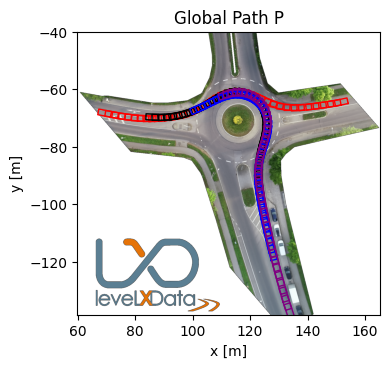

In [16]:
plt.figure(figsize=(4, 4), tight_layout = True)
plt.xlim(x_low, x_up)
plt.ylim(y_low, y_up_viz)

for k in range(len(State_EV[0])):
    
    x_SV0, y_SV0 = rota_rect(State_SV0[:, k], l_veh_sv0, w_veh_sv0)
    x_SV1, y_SV1 = rota_rect(State_SV1[:, k], l_veh_sv1, w_veh_sv1)
    x_SV2, y_SV2 = rota_rect(State_SV2[:, k], l_veh_sv2, w_veh_sv2)
    x_EV, y_EV   = rota_rect(State_EV[:, k], l_veh, w_veh)

    plt.plot(x_SV0, y_SV0, c = 'k', linewidth = 1)
    plt.plot(x_SV1, y_SV1, c = 'b', linewidth = 1)
    plt.plot(x_SV2, y_SV2, c = 'purple', linewidth = 1)
    plt.plot(x_EV, y_EV,   c = 'r', linewidth = 1)
img = mpimg.imread('00_background.png')
plt.imshow(img, extent=[x_low, x_up, y_low, y_up])
plt.title("Global Path P")   
plt.xlabel("x [m]")
plt.ylabel("y [m]")

Text(0, 0.5, 'Minimum Distance w.r.t SV[m]')

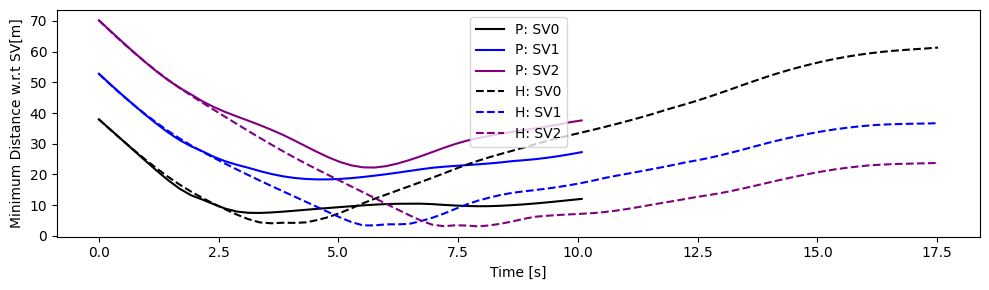

In [17]:
plt.figure(figsize=(10, 3), tight_layout = True)
plt.plot(t, Min_Dis_SV0_P,  color = 'k',  linewidth=1.5,  label = 'P: SV0')
plt.plot(t, Min_Dis_SV1_P,  color = 'b',   linewidth=1.5,  label = 'P: SV1')
plt.plot(t, Min_Dis_SV2_P,  color = 'purple', linewidth=1.5,  label = 'P: SV2')
plt.plot(EV_Data['t'], Min_Dis_SV0_H,  'k--',  linewidth=1.5,  label = 'H: SV0')
plt.plot(EV_Data['t'], Min_Dis_SV1_H,  'b--',   linewidth=1.5,  label = 'H: SV1')
plt.plot(EV_Data['t'], Min_Dis_SV2_H,  color = 'purple', linestyle = '--', linewidth=1.5,  label = 'H: SV2')
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Minimum Distance w.r.t SV[m]")

Text(0, 0.5, 'Local Vel. [m/s]')

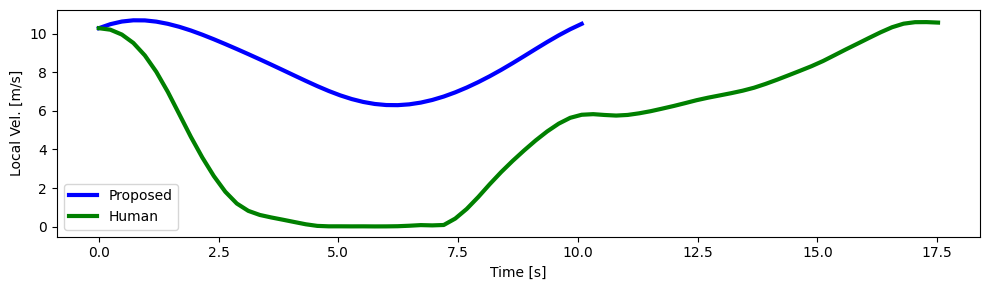

In [18]:
plt.figure(figsize=(10, 3), tight_layout = True)
plt.plot(t, State_EV[3, :],  color = 'blue', linewidth=3,   label = 'Proposed')
plt.plot(EV_Data['t'], EV_Data['v'], color = 'green', linewidth=3,   label = 'Human')
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Local Vel. [m/s]")

Text(0, 0.5, 'Local Acc. [m/s^s]')

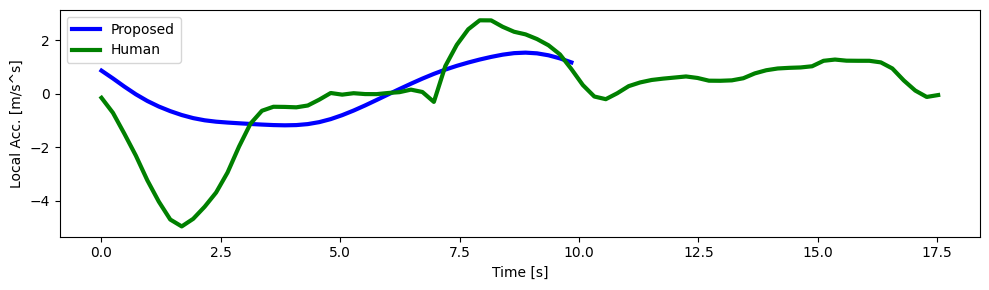

In [19]:
plt.figure(figsize=(10, 3), tight_layout = True)
plt.plot(t[0:-1], Control_EV[0, :],  color = 'blue', linewidth=3,   label = 'Proposed')
plt.plot(EV_Data['t'], EV_Data['a'], color = 'green', linewidth=3,   label = 'Human')
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Local Acc. [m/s^s]")